# Trabalho 02 — Redes Neurais: Fashion-MNIST

**UFSC · Sistemas Inteligentes (INE5633)**  
**Professora:** Nathalia da Cruz Alves  
**Entrega:** 15/11/2026 · grupo de 2 a 3 estudantes

## Equipe e contribuições

| Estudante | Contribuição efetiva |
| --- | --- |
| Preencher | Descrever em uma frase |
| Preencher | Descrever em uma frase |

Adicionar uma terceira linha se necessário.

**Estado deste notebook:** base inicial com preparação dos dados executável.
As arquiteturas, os treinamentos, a busca e as análises serão desenvolvidos pela equipe.
As seções abaixo seguem o [enunciado](<Trabalho Prático 2 - Redes Neurais.pdf>).

## Plano de desenvolvimento

1. Preparar o ambiente, carregar e conhecer os dados.
2. Treinar uma **MLP sem convoluções** e analisar loss/acurácia de treino e validação.
3. Treinar uma **CNN com aumento de dados**, analisar as curvas e comparar com a MLP.
4. Testar hiperparâmetros da CNN e organizar uma tabela dos experimentos.
5. Avaliar a melhor CNN no teste, com loss, acurácia e matriz de confusão.
6. Elaborar conclusões, registrar referências e preparar o vídeo de até 8 minutos.

Antes de cada implementação, explicar a escolha e o conceito envolvido.
Preencher as análises com os resultados medidos e manter as saídas das células salvas.

## 1. Ambiente e reprodutibilidade

Usaremos TensorFlow/Keras, como nas aulas práticas. A seed 42 controla a divisão
estratificada e as fontes usuais de aleatoriedade. As versões e os dispositivos são
registrados para permitir comparar execuções; desempenho e reprodução podem variar
entre ambientes. O notebook pode rodar em CPU, embora os treinamentos sejam mais lentos.

Abra este arquivo pelo Jupyter da disciplina ou instale `requirements.txt` em um
ambiente virtual. O Keras Tuner será necessário somente na etapa de otimização.

In [1]:
import gzip
import importlib.metadata
import json
from pathlib import Path
import platform
import struct
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)

# O kernel deve partir desta pasta ou de um de seus subdiretórios.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'scripts' / 'baixar_dados.py').is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError('Abra o notebook na pasta Trabalho 02 do repositório.')

DADOS = RAIZ / 'dados' / 'fashion-mnist'
RESULTADOS = RAIZ / 'resultados'
MODELOS = RAIZ / 'modelos'
for pasta in (RESULTADOS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

versoes = {'python': platform.python_version()}
for pacote in ('tensorflow', 'numpy', 'pandas', 'matplotlib', 'scikit-learn'):
    versoes[pacote] = importlib.metadata.version(pacote)
print(json.dumps(versoes, indent=2))
print('GPUs disponíveis:', tf.config.list_physical_devices('GPU'))
print('Seed:', SEED)
(RESULTADOS / 'ambiente.json').write_text(
    json.dumps({'seed': SEED, 'versoes': versoes}, indent=2), encoding='utf-8'
)

I0000 00:00:1793922463.352522    3876 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793922463.943245    3876 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793922466.222972    3876 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


{
  "python": "3.13.14",
  "tensorflow": "2.21.0",
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "matplotlib": "3.11.1",
  "scikit-learn": "1.9.0"
}
GPUs disponíveis: []
Seed: 42


E0000 00:00:1793922467.748182    3876 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


190

## 2. Download e carregamento do Fashion-MNIST

O [dataset oficial da Zalando](https://github.com/zalandoresearch/fashion-mnist)
contém imagens de roupas 28 × 28 em escala de cinza e dez rótulos. Existem
60.000 exemplos no treino oficial e 10.000 no teste. Os quatro arquivos compactados
são guardados em `dados/fashion-mnist/`, fora do versionamento.

O script verifica os checksums MD5 publicados antes de reaproveitar arquivos.
Com os dados íntegros no disco, esta etapa funciona sem rede. O leitor abaixo usa
o formato IDX original, conferindo cabeçalhos e tamanhos; não utiliza o MNIST de dígitos.

In [2]:
subprocess.run([sys.executable, str(RAIZ / 'scripts' / 'baixar_dados.py')], check=True)


def carregar_idx(prefixo):
    with gzip.open(DADOS / f'{prefixo}-images-idx3-ubyte.gz', 'rb') as arquivo:
        magic, quantidade, altura, largura = struct.unpack('>IIII', arquivo.read(16))
        assert magic == 2051 and (altura, largura) == (28, 28)
        imagens = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert imagens.size == quantidade * altura * largura
        imagens = imagens.reshape(quantidade, altura, largura)
    with gzip.open(DADOS / f'{prefixo}-labels-idx1-ubyte.gz', 'rb') as arquivo:
        magic, total_rotulos = struct.unpack('>II', arquivo.read(8))
        assert magic == 2049 and total_rotulos == quantidade
        rotulos = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert rotulos.size == quantidade and np.all(rotulos < 10)
    return imagens, rotulos


# Carregar o teste somente na seção 6, após selecionar o modelo.
X_oficial, y_oficial = carregar_idx('train')
assert X_oficial.shape == (60000, 28, 28)
print('Treino oficial:', X_oficial.shape, y_oficial.shape)
print('Pixels:', X_oficial.dtype, '| intervalo:', X_oficial.min(), X_oficial.max())

OK (já disponível): train-images-idx3-ubyte.gz
OK (já disponível): train-labels-idx1-ubyte.gz
OK (já disponível): t10k-images-idx3-ubyte.gz
OK (já disponível): t10k-labels-idx1-ubyte.gz
Dados disponíveis em: /home/jovyan/work/Trabalho 02/dados/fashion-mnist


Treino oficial: (60000, 28, 28) (60000,)
Pixels: uint8 | intervalo: 0 255


## 3. Separação de treino/validação e exploração

Reservamos 20% do treino oficial para validação, preservando a proporção das
classes por estratificação. Todos os modelos devem usar os mesmos índices: isso
permite comparar MLP, CNN e configurações sem alterar a dificuldade da validação.
Os índices são salvos em `resultados/divisao_dados.npz`.

Exploramos somente dados de treino. Os rótulos abaixo são traduções dos nomes
publicados pela Zalando; a numeração original é preservada.

,classe,treino,validacao
0,Camiseta/top,4800,1200
1,Calça,4800,1200
2,Suéter,4800,1200
3,Vestido,4800,1200
4,Casaco,4800,1200
5,Sandália,4800,1200
6,Camisa,4800,1200
7,Tênis,4800,1200
8,Bolsa,4800,1200
9,Bota de cano curto,4800,1200


Treino: 48000 | Validação: 12000


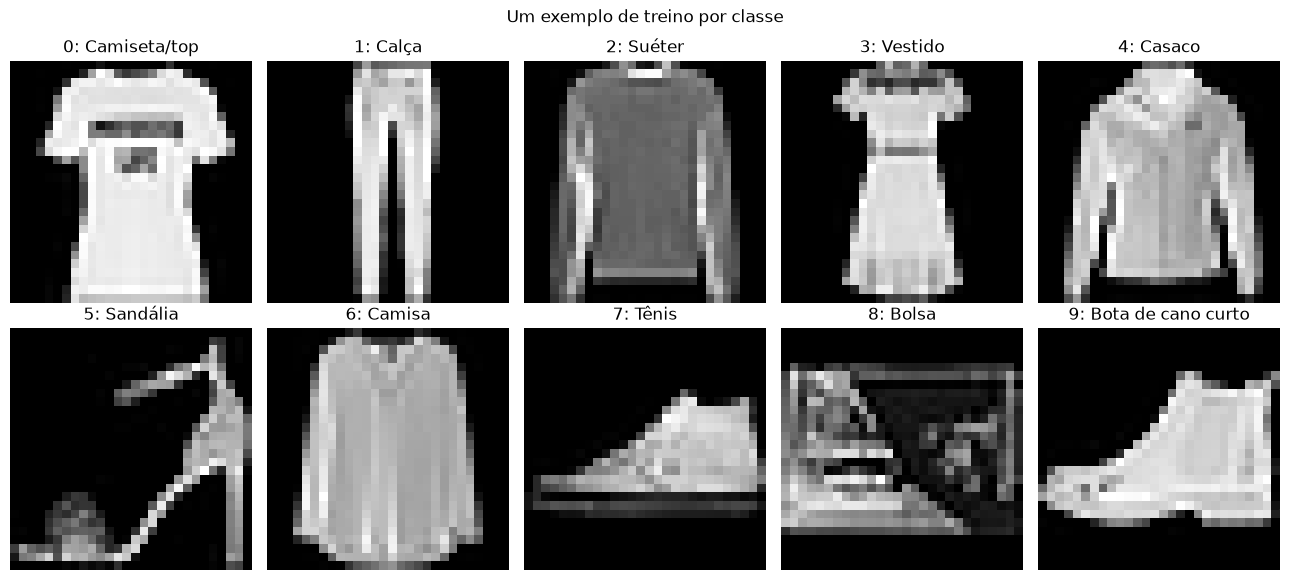

In [3]:
NOMES_CLASSES = [
    'Camiseta/top', 'Calça', 'Suéter', 'Vestido', 'Casaco',
    'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota de cano curto',
]
indices_treino, indices_validacao = train_test_split(
    np.arange(len(y_oficial)), test_size=0.2, random_state=SEED,
    stratify=y_oficial,
)
assert not np.intersect1d(indices_treino, indices_validacao).size
assert len(indices_treino) + len(indices_validacao) == len(y_oficial)
np.savez(RESULTADOS / 'divisao_dados.npz',
         treino=indices_treino, validacao=indices_validacao, seed=SEED)

contagens = pd.DataFrame({
    'classe': NOMES_CLASSES,
    'treino': np.bincount(y_oficial[indices_treino], minlength=10),
    'validacao': np.bincount(y_oficial[indices_validacao], minlength=10),
})
display(contagens)
print(f'Treino: {len(indices_treino)} | Validação: {len(indices_validacao)}')

fig, eixos = plt.subplots(2, 5, figsize=(13, 6))
for classe, eixo in enumerate(eixos.flat):
    candidatos = indices_treino[y_oficial[indices_treino] == classe]
    eixo.imshow(X_oficial[candidatos[0]], cmap='gray', vmin=0, vmax=255)
    eixo.set_title(f'{classe}: {NOMES_CLASSES[classe]}')
    eixo.axis('off')
fig.suptitle('Um exemplo de treino por classe')
fig.tight_layout()
fig.savefig(RESULTADOS / 'exemplos_treino.png', dpi=150, bbox_inches='tight')
plt.show()

### Normalização e formato das entradas

Convertemos os pixels para `float32` e dividimos por 255 para usar a escala [0, 1].
A transformação é fixa e não estima estatísticas da validação. Mantemos um canal
explícito para a CNN: `(amostras, 28, 28, 1)`. A MLP poderá receber o mesmo tensor
e usar uma camada `Flatten` para convertê-lo em um vetor de 784 valores.

Aumento de dados será aplicado apenas durante o treinamento da CNN. Validação
e teste devem preservar as imagens originais normalizadas.

In [4]:
X_train = X_oficial[indices_treino].astype('float32')[..., np.newaxis] / 255.0
X_val = X_oficial[indices_validacao].astype('float32')[..., np.newaxis] / 255.0
y_train = y_oficial[indices_treino]
y_val = y_oficial[indices_validacao]

assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert 0 <= X_train.min() <= X_train.max() <= 1
print('Treino:', X_train.shape, y_train.shape, X_train.dtype)
print('Validação:', X_val.shape, y_val.shape, X_val.dtype)
print('Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.')

Treino: (48000, 28, 28, 1) (48000,) float32
Validação: (12000, 28, 28, 1) (12000,) float32
Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.


## 4. MLP: implementação, treinamento e análise (item 1)

**A desenvolver pela equipe.** Antes do código, explicar a arquitetura escolhida:
quantidade de camadas e neurônios, ativações, saída para dez classes, função de
perda e otimizador. A MLP não deve conter convoluções.

Registrar taxa de aprendizagem, batch size, épocas, seed e critério de parada.
Usar `validation_data=(X_val, y_val)` para manter a divisão definida acima.
Apresentar curvas de **loss e acurácia de treino e validação por época**.

In [5]:
# TODO: construir e compilar a MLP; mostrar model.summary().
# TODO: executar fit com treino e validação e salvar o histórico real.
# TODO: gerar e salvar os gráficos de loss e acurácia por época.

### Análise da MLP — preencher após executar

- Como a acurácia e a função de perda escolhida são calculadas?
- Por que elas não são necessariamente proporcionais? Relacione a explicação às curvas.
- O desempenho é satisfatório? Justifique com os valores observados.
- Existem indícios de sobreajuste ou subajuste? O que a validação sugere sobre generalização?

**Resposta da equipe:** preencher.

## 5. CNN com aumento de dados (item 2)

**A desenvolver pela equipe.** Explicar convolução, pooling e as transformações
escolhidas antes da implementação. Justificar por que essas transformações preservam
o significado das roupas e verificar visualmente exemplos transformados.

Treinar com a mesma divisão de dados da MLP. Mostrar a arquitetura, registrar a
configuração e plotar loss/acurácia de treino e validação por época.

In [6]:
# TODO: criar e visualizar o aumento de dados aplicado somente no treino.
# TODO: construir, compilar e treinar a CNN com validação explícita.
# TODO: salvar os históricos e gerar as quatro curvas, como na MLP.

### Análise da CNN — preencher após executar

- Qual a finalidade do aumento de dados e como pode ajudar a generalização?
- O desempenho é satisfatório? Quais resultados sustentam a conclusão?
- Há sobreajuste ou subajuste? Como loss e acurácia se comportam?
- Como a CNN se compara à MLP, considerando desempenho e custo do treinamento?

**Resposta da equipe:** preencher.

## 5.1. Experimentação e otimização da CNN (item 3)

**A desenvolver pela equipe.** Definir o espaço de busca, o orçamento de tentativas,
a métrica de seleção e a estratégia (por exemplo, Random Search, como na aula 23).
Justificar os intervalos antes de testar. Se utilizar Keras Tuner no Docker, instalar
`keras-tuner` no kernel com `%pip install keras-tuner`.

Comparar configurações mantendo divisão, condições e orçamento documentados.
Selecionar o melhor modelo **somente pela validação**, sem usar o conjunto de teste.
Registrar uma linha por tentativa: identificação, camadas/filtros, neurônios,
dropout, learning rate, batch size, épocas executadas, loss/acurácia de validação
e tempo. Indicar a regra usada para escolher a melhor época/modelo.

In [7]:
# TODO: implementar a busca e executar os experimentos.
# TODO: apresentar uma tabela preenchida com as configurações e métricas reais.
# TODO: salvar a tabela em resultados/experimentos_cnn.csv.
# TODO: guardar o melhor modelo e sua configuração, conforme a validação.

### Análise dos hiperparâmetros — preencher após executar

Indicar os melhores valores e discutir quais combinações mais alteraram o
resultado. Relacionar as diferenças à capacidade do modelo, regularização e
otimização, reconhecendo quando vários fatores mudaram simultaneamente.

**Resposta da equipe:** preencher.

## 6. Avaliação final no teste (item 4)

**Executar apenas após finalizar a seleção da CNN.** Carregar as 10.000 imagens de
teste com `carregar_idx('t10k')`, normalizar com a mesma transformação e adicionar
o canal. Utilizar o melhor modelo selecionado na seção anterior.

Apresentar loss e acurácia finais, previsões e matriz de confusão com os nomes das
dez classes. Discutir as confusões mais frequentes e a capacidade de generalização.
O resultado de teste não deve orientar novas escolhas de hiperparâmetros.

In [8]:
# TODO: carregar e preparar o teste, usando a mesma escala e formato do treino.
# TODO: avaliar a melhor CNN e apresentar loss e acurácia finais.
# TODO: gerar previsões e matriz de confusão com as dez classes identificadas.

### Discussão final — preencher após executar

Comparar teste e validação, comentar as classes mais confundidas e discutir as
limitações dos experimentos. Retomar a comparação entre MLP e CNN com as métricas
medidas, sem presumir que uma arquitetura necessariamente foi superior.

**Resposta da equipe:** preencher.

## 7. Checklist de entrega

- [ ] Nomes dos participantes e contribuição de cada um preenchidos.
- [ ] Explicações conceituais antes das implementações.
- [ ] MLP e CNN treinadas com curvas e análises.
- [ ] Tabela de hiperparâmetros, melhores valores e justificativa.
- [ ] Avaliação final com loss, acurácia e matriz de confusão.
- [ ] Notebook executado em ordem, com as saídas reais salvas.
- [ ] Referências e finalidades do uso de IA atualizadas.
- [ ] Vídeo de até 8 minutos e links de entrega conferidos.

## 8. Referências e registro de apoio

- Profa. Nathalia da Cruz Alves: enunciado, slides em `Conteudo/` e notebooks em
  `Aulas_Praticas/`. Manter a autoria quando adaptar materiais das aulas.
- Han Xiao, Kashif Rasul e Roland Vollgraf (2017).
  [Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms](https://arxiv.org/abs/1708.07747).
- [Repositório oficial do Fashion-MNIST: dados, classes e checksums](https://github.com/zalandoresearch/fashion-mnist).
- **OpenAI Codex:** apoio à organização inicial, documentação, download e criação
  desta base de notebook. Os treinamentos e as análises ainda não foram realizados.
  A equipe deve revisar este material e atualizar o registro conforme seu uso real.
  O enunciado recomenda IA apenas para apoio à pesquisa e estabelece critérios de
  autoria e limites de uso que devem ser observados pela equipe.